<a href="https://colab.research.google.com/github/yamenetoo/fractional-delayed-fault-model/blob/main/fault_study_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
49eb95d Fix preview cell order
d8b14e8 Add parallel run_all.py and Colab notebook that clones the repo
bbc6378 Professional logo (light and dark variants)
MODE=FULL  CFG={'R1': 24, 'B1': 40, 'R2': 16, 'B2': 24, 'M': 12}  CPU cores=2
128 tasks on 2 processes
[1/128] alt_T400_sy0.3_000.json  elapsed 0s
[2/128] alt_T400_sy1.5_000.json  elapsed 0s
[3/128] alt_T400_sy0.3_001.json  elapsed 0s
[4/128] alt_T400_sy1.5_001.json  elapsed 0s
[5/128] alt_T400_sy0.3_002.json  elapsed 0s
[6/128] alt_T400_sy1.5_002.json  elapsed 0s
[7/128] alt_T400_sy0.3_003.json  elapsed 0s
[8/128] alt_T400_sy1.5_003.json  elapsed 0s
[9/128] alt_T400_sy0.3_004.json  elapsed 0s
[10/128] alt_T400_sy0.3_005.json  elapsed 0s
[11/128] alt_T400_sy1.5_004.json  elapsed 347s
[12/128] alt_T400_sy1.5_005.json  elapsed 361s
[13/128] alt_T400_sy1.5_006.json  elapsed 482s
[14/128] alt_T400_sy0.3_007.jso

/usr/local/lib/python3.13/dist-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


fault_map.pdf


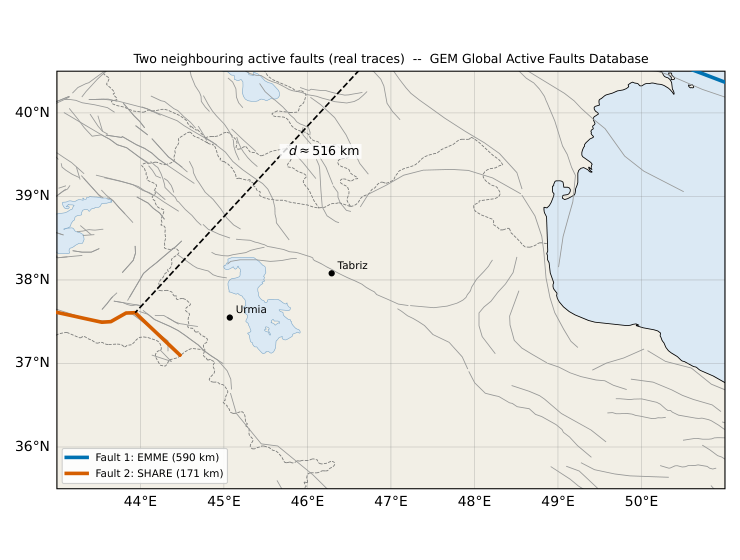

forecast_eval.pdf


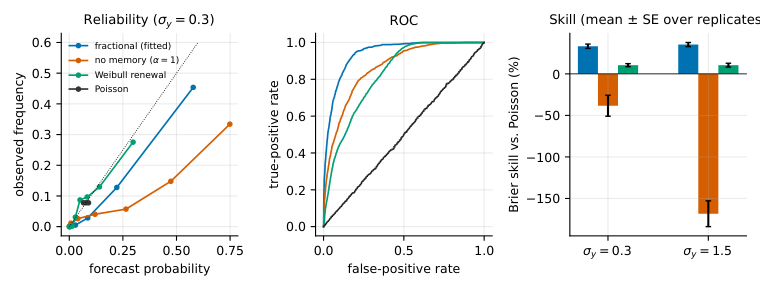

loading_calibration.pdf


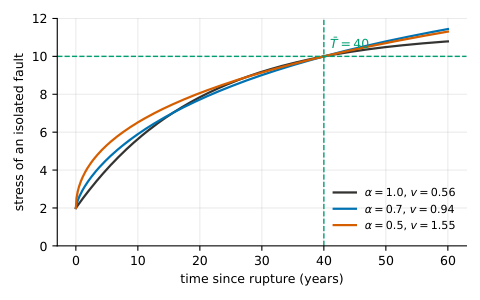

lr_tests.pdf


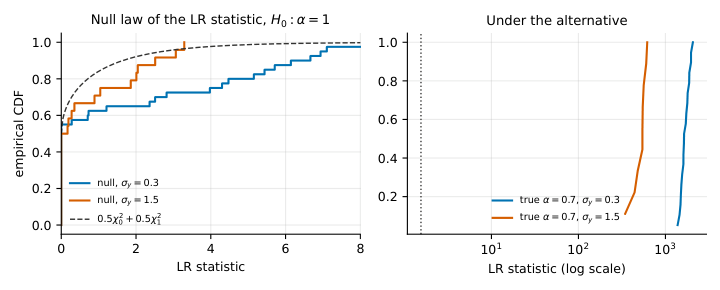

profile_alpha.pdf


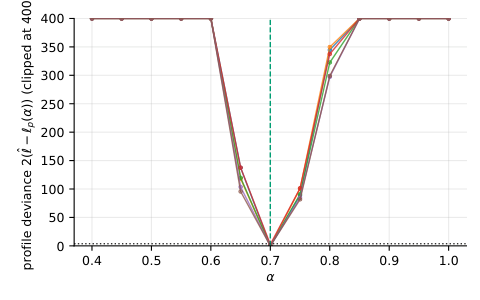

recovery_box.pdf


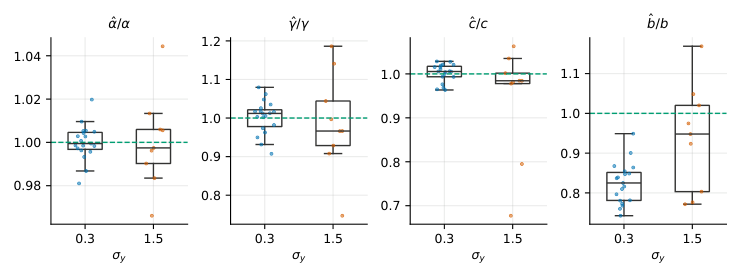

sim_dataset.pdf


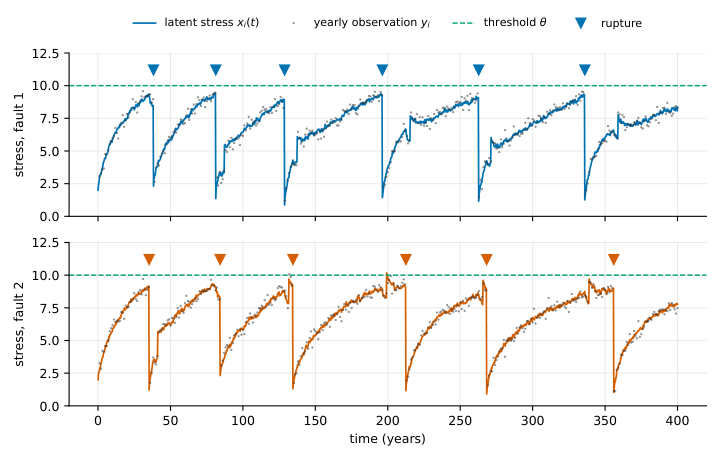

slices.pdf


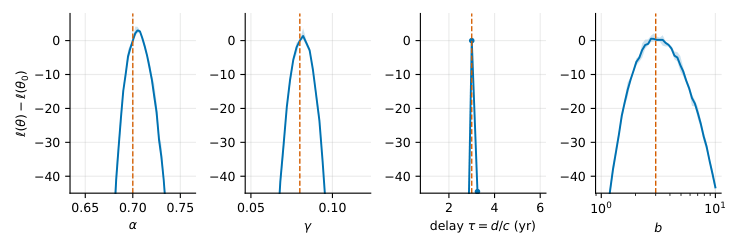

soe_kernel.pdf


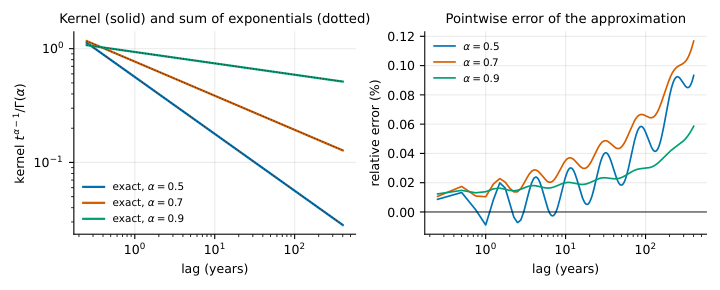


تم. كل النتائج في: /content/drive/MyDrive/fault_study
أرسل لي summary.json و results.xlsx من هذا المجلد لتحديث المقالة.


In [ ]:
# ===== خلية واحدة: استنساخ المستودع + تشغيل كل الدراسة بالتوازي + حفظ كل شيء في Drive =====
MODE        = 'FULL'    # 'QUICK' = فحص سريع (دقائق)، 'FULL' = دراسة المقالة (~1.5 ساعة على نواتين)
FAULT1      = 'EMME'    # اسم (جزء من الاسم) الصدع الأول في قاعدة GEM
FAULT2      = 'SHARE'   # الصدع الثاني
COMPILE_PDF = False     # True = يثبّت LaTeX ويجمّع article.pdf داخل Colab (+3-5 دقائق)

import os, sys, glob, json, getpass, zipfile, subprocess, multiprocessing
from google.colab import drive

def sh(cmd, cwd=None, env=None, hide=None):
    """تشغيل أمر مع عرض مباشر للمخرجات"""
    p = subprocess.Popen(cmd, shell=True, cwd=cwd, env=env, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line.replace(hide, '***') if hide else line, end='')
    p.wait()
    if p.returncode:
        raise RuntimeError(f'command failed ({p.returncode}): {cmd}')

# 1) Drive
drive.mount('/content/drive')
DRIVE = '/content/drive/MyDrive/fault_study'
for d in ('out', 'figs', 'tabs', 'data'):
    os.makedirs(f'{DRIVE}/{d}', exist_ok=True)

# 2) المستودع (إن كان خاصًا يطلب رمز GitHub بصلاحية قراءة)
REPO, SRC = 'yamenetoo/fractional-delayed-fault-model', '/content/repo'
if os.path.isdir(f'{SRC}/.git'):
    sh('git pull -q', cwd=SRC)
else:
    r = subprocess.run(f'git clone -q https://github.com/{REPO} {SRC}', shell=True, capture_output=True, text=True)
    if r.returncode:
        tok = getpass.getpass('Repository is private - paste a GitHub token (hidden): ')
        sh(f'git clone -q https://{tok}@github.com/{REPO} {SRC}', hide=tok)
sh('git log --oneline | head -3', cwd=SRC)

# 3) المكتبات + ربط مجلدات النتائج بـ Drive
sh('pip -q install numba openpyxl cartopy pymupdf 2>&1 | tail -1; apt-get -qq install -y libgeos-dev >/dev/null')
ST = f'{SRC}/stats'
for d in ('out', 'figs', 'tabs', 'data'):
    sh(f'rm -rf {d} && ln -sfn {DRIVE}/{d} {d}', cwd=ST)
NCPU = multiprocessing.cpu_count()
CFG = dict(QUICK=dict(R1=3, B1=6, R2=3, B2=6, M=2), FULL=dict(R1=24, B1=40, R2=16, B2=24, M=12))[MODE]
print(f'MODE={MODE}  CFG={CFG}  CPU cores={NCPU}')

# 4) كل الدراسة بالتوازي (قابلة للاستئناف: أعد تشغيل الخلية إن انقطع الاتصال)
sh(f"python -u run_all.py --procs {NCPU} --R1 {CFG['R1']} --B1 {CFG['B1']} --R2 {CFG['R2']} "
   f"--B2 {CFG['B2']} --M {CFG['M']} --npart 100 --out out", cwd=ST)

# 5) خريطة الصدعين + الأشكال + الجداول + Excel
env = dict(os.environ, FAULT1=FAULT1, FAULT2=FAULT2)
sh('python fault_map.py', cwd=ST, env=env)
for s in ('fig_basic.py', 'analyze.py', 'export_excel.py'):
    sh(f'python {s}', cwd=ST)
sh(f'cp summary.json results.xlsx {DRIVE}/', cwd=ST)

# 6) حزمة المقالة (فكّها ثم pdflatex داخل paper/)
with zipfile.ZipFile(f'{DRIVE}/article_bundle.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in glob.glob(f'{SRC}/paper/*.tex'):
        z.write(f, 'paper/' + os.path.basename(f))
    z.write(f'{ST}/schematic.tex', 'stats/schematic.tex')
    for sub in ('figs', 'tabs'):
        for f in glob.glob(f'{DRIVE}/{sub}/*'):
            z.write(f, f'stats/{sub}/' + os.path.basename(f))

# 7) (اختياري) تجميع PDF
if COMPILE_PDF:
    sh('apt-get -qq install -y texlive-latex-recommended texlive-latex-extra texlive-fonts-recommended >/dev/null')
    sh('pdflatex -interaction=nonstopmode article.tex >/dev/null; pdflatex -interaction=nonstopmode article.tex | tail -3',
       cwd=f'{SRC}/paper')
    sh(f'cp article.pdf {DRIVE}/article.pdf', cwd=f'{SRC}/paper')

# 8) معاينة الأشكال
import fitz
from IPython.display import Image, display
for f in sorted(glob.glob(f'{DRIVE}/figs/*.pdf')):
    png = f[:-4] + '.png'
    fitz.open(f)[0].get_pixmap(dpi=100).save(png)
    print(os.path.basename(f)); display(Image(png))

print('\nتم. كل النتائج في:', DRIVE)
print('أرسل لي summary.json و results.xlsx من هذا المجلد لتحديث المقالة.')